<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/sunspots.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Forecasting the sunspot number

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*



Dark spots appear on the surface of the Sun, regions where strong magnetic fields suppress the flow of heat from the interior, so that they are cooler and darker than their surroundings. Their number rises and falls in a cycle of about eleven years, the solar cycle, which was discovered by Heinrich Schwabe in the 1840s. At the maximum of a cycle the Sun shows hundreds of spots and produces many flares and eruptions of magnetised plasma. At the minimum it can be free of spots for weeks. Since 1848, when Rudolf Wolf introduced it in Zurich, the activity has been measured by the sunspot number, and the record has been reconstructed back to 1749.

Forecasting solar activity has a practical side. Flares and eruptions cause geomagnetic storms at the Earth, which disturb radio communication and satellite navigation, increase the drag on satellites in low orbits and induce currents in long power lines. Space agencies plan missions with forecasts of the coming cycle. The sunspot number is also one of the classic test signals of time-series analysis. It is nearly periodic, with a clear cycle, and yet the length and especially the height of each cycle vary in a way that is hard to predict.

We analyse the sunspot record using the same procedure as for the weather in central England. The measurement of the sunspot number and the source of the record establish what each value represents. The time plot, histogram, autocorrelation function, power spectrum and delay plot describe its statistical properties. We determine the delay and dimension of a delay embedding and forecast the monthly sunspot number up to 20 months ahead with the models of the lecture, from the autoregressive (AR), moving-average (MA) and combined (ARMA) models through the nonlinear vector autoregression (NVAR) to a multilayer perceptron (MLP), an Elman recurrent neural network (RNN) and a long short-term memory network (LSTM). For every model we plot the forecasts against the true values at the horizons τ = 1, 5 and 20 months and the capacity C(τ) against τ, and we collect the total capacities in one table.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The setting `JAX_PLATFORMS=cpu` selects CPU execution, which takes a few minutes.
> 2. `jax`, `flax`, `optax`, `statsmodels`, `scikit-learn`, `scipy`, `pandas` and `matplotlib` are pre-installed in Colab.
> 3. The data are downloaded from the World Data Center SILSO of the Royal Observatory of Belgium during execution, so an internet connection is needed.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)
import time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats
import scipy.signal
import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx
import sklearn
from sklearn.neural_network import MLPRegressor
import statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf
warnings.filterwarnings("ignore", module="statsmodels")
warnings.filterwarnings("ignore", category=sklearn.exceptions.ConvergenceWarning)

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| statsmodels", statsmodels.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | statsmodels 0.14.4 | scikit-learn 1.6.1


<hr/>
## 1. The sunspot number

The sunspot number of one day is computed from the count of spots seen on the visible disc of the Sun. An observer counts the groups of spots g and the individual spots s, and forms Wolf's number
$$R=10\,g+s . \tag{1}$$
The factor 10 gives a group about the weight of ten single spots, so that the number follows the total activity. The counts depend on the telescope, the observer and the seeing, so every station has a personal scaling factor, and the international sunspot number combines the observations of a worldwide network of stations into one daily value. The series was recalibrated in 2015, and the current version 2.0 removes several inconsistencies of the older series [F. Clette, L. Svalgaard, J. M. Vaquero, E. W. Cliver, Space Sci. Rev. **186**, 35 (2014), [doi:10.1007/s11214-014-0074-2](https://doi.org/10.1007/s11214-014-0074-2)].

One sample of our record is the monthly mean total sunspot number, the average of the daily values over one calendar month, a dimensionless number of zero or more. The record starts in January 1749. The file has seven columns, the year, the month, the date as a fraction of the year, the monthly mean, the standard deviation of the daily values from the individual stations, the number of observations used, and a marker that is 1 for definitive values and 0 for the last months, which are still provisional. For the oldest months the standard deviation and the number of observations are unknown and given as −1. The record has no labels, and the task is to forecast later values of the record from earlier ones.

> Source: WDC-SILSO, Royal Observatory of Belgium, Brussels, *Monthly mean total sunspot number*, version 2.0, <https://www.sidc.be/SILSO/datafiles>. The data are distributed under the licence CC BY-NC 4.0.

In [2]:
SUN_URL = "https://www.sidc.be/SILSO/INFO/snmtotcsv.php"
SUN_FILE = "data/SN_m_tot_V2.0.csv"
if not os.path.exists(SUN_FILE):
    urllib.request.urlretrieve(SUN_URL, SUN_FILE)
sun = pd.read_csv(SUN_FILE, sep=";", header=None,
                  names=["year", "month", "date", "ssn", "std", "n_obs", "definitive"])
t_sun, ssn = sun["date"].to_numpy(), sun["ssn"].to_numpy(float)
DT = 1.0 / 12.0                                   # sampling interval in years
print(f"{len(sun)} months, {int(sun.year.iloc[0])}-{int(sun.month.iloc[0]):02d} to {int(sun.year.iloc[-1])}-{int(sun.month.iloc[-1]):02d}")
print(f"provisional months: {int((sun.definitive == 0).sum())}, months without station statistics: {int((sun.n_obs < 0).sum())}")
print(f"observations per month in the last year: {int(sun.n_obs.iloc[-12:].min())} to {int(sun.n_obs.iloc[-12:].max())}")
print(sun.tail(4).to_string(index=False))

3333 months, 1749-01 to 2026-09
provisional months: 3, months without station statistics: 828
observations per month in the last year: 736 to 1371
 year  month     date  ssn  std  n_obs  definitive
 2026      6 2026.453 93.3 15.1   1316           1
 2026      7 2026.538 78.1 11.2   1371           0
 2026      8 2026.623 76.0 12.3   1248           0
 2026      9 2026.705 60.3 13.0   1117           0


The record has 3333 months, from January 1749 to September 2026. The last three months are provisional. For the first 828 months the station statistics are unknown, and in the last year between 736 and 1371 observations entered each monthly mean.

The visible-light photograph of the Sun on 10 May 2024 was taken by the Helioseismic and Magnetic Imager on board NASA's Solar Dynamics Observatory, a satellite that has photographed the Sun continuously since 2010. The dark patches are sunspots. Most of them appear in groups, and the large group in the lower right was one of the most active of the present cycle. The monthly sunspot number of May 2024 provides a comparison between the visible spots and their numerical representation in the record.

> Image: NASA/SDO and the HMI science team, <https://sdo.gsfc.nasa.gov>. NASA images are generally not subject to copyright and may be used for educational purposes.

monthly mean sunspot number of May 2024: 172.1 (record maximum 398.2, mean 82.2)


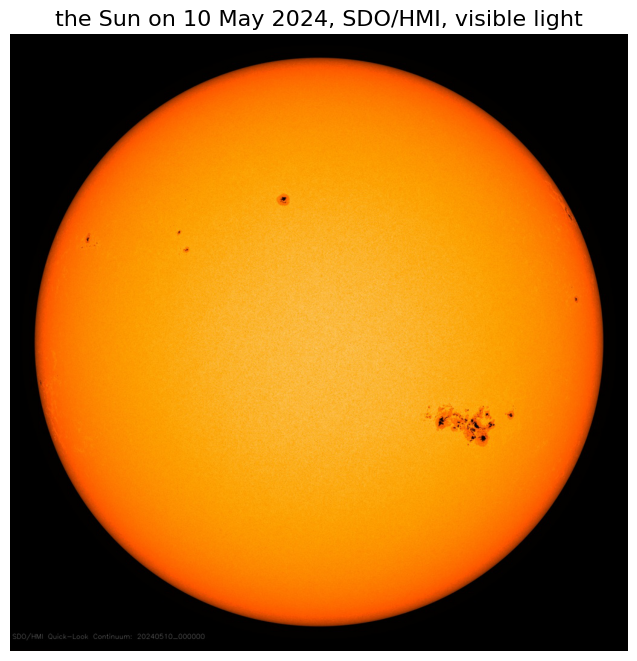

In [3]:
SDO_URL = "https://sdo.gsfc.nasa.gov/assets/img/browse/2024/05/10/20240510_000000_1024_HMIIC.jpg"
SDO_FILE = "data/sdo_hmi_20240510.jpg"
if not os.path.exists(SDO_FILE):
    urllib.request.urlretrieve(SDO_URL, SDO_FILE)
img = plt.imread(SDO_FILE)
fig, ax = plt.subplots(figsize=(6.5, 6.5), layout="constrained")
ax.imshow(img); ax.axis("off")
ax.set_title("the Sun on 10 May 2024, SDO/HMI, visible light")
plt.show()
may24 = sun[(sun.year == 2024) & (sun.month == 5)]
print(f"monthly mean sunspot number of May 2024: {float(may24.ssn.iloc[0]):.1f} "
      f"(record maximum {ssn.max():.1f}, mean {ssn.mean():.1f})")

An observer turns a view of the disc into Wolf's number of equation (1) by grouping the spots. Spots that lie close together and evolve together form a group, and the observer counts the groups g and all individual spots s.

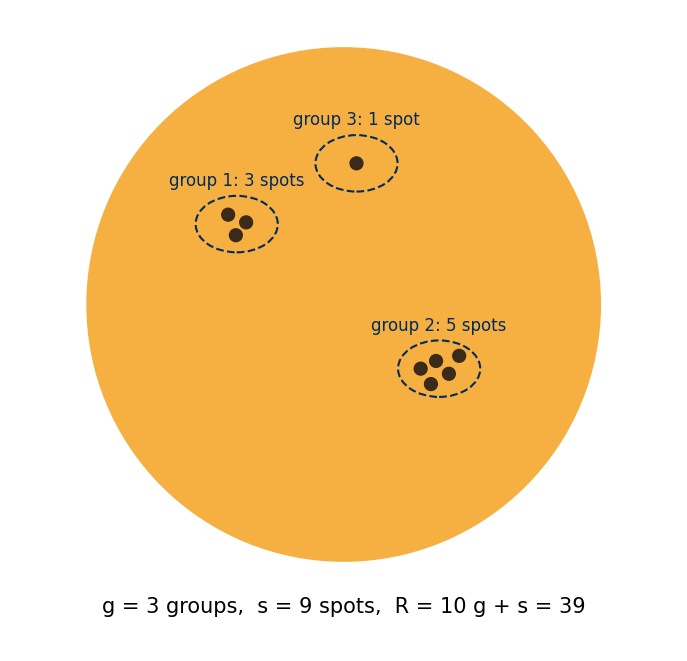

In [4]:
# sketch of the count behind the sunspot number R = 10 g + s
from matplotlib.patches import Circle, Ellipse
groups = [[(-0.45, 0.35), (-0.38, 0.32), (-0.42, 0.27)],                      # a group of 3 spots
          [(0.30, -0.25), (0.36, -0.22), (0.41, -0.27), (0.34, -0.31), (0.45, -0.20)],   # a group of 5 spots
          [(0.05, 0.55)]]                                                    # a single spot is a group too
fig, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
ax.add_patch(Circle((0, 0), 1, color="#F6B042"))
for i, g in enumerate(groups):
    for (xg, yg) in g:
        ax.add_patch(Circle((xg, yg), 0.025, color="#3B2A1A"))
    cx, cy = np.mean(g, axis=0)
    ax.add_patch(Ellipse((cx, cy), 0.32, 0.22, fill=False, ls="--", lw=1.5, color=UJNavy))
    ax.text(cx, cy + 0.15, f"group {i + 1}: {len(g)} spot" + ("s" if len(g) > 1 else ""), ha="center", fontsize=12, color=UJNavy)
g_count, s_count = len(groups), sum(len(g) for g in groups)
ax.text(0, -1.2, f"g = {g_count} groups,  s = {s_count} spots,  R = 10 g + s = {10 * g_count + s_count}",
        ha="center", fontsize=15)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.35, 1.15); ax.set_aspect("equal"); ax.axis("off")
plt.show()

<hr/>
## 2. Statistical properties of a record

The statistical properties of a record indicate which forecasts can be expected to work. We examine its distribution, temporal correlations and periodic components before fitting a model.

The mean and the standard deviation give the level and the typical size of the fluctuations, and the histogram shows the distribution of the values, whether it is symmetric, bounded or has long tails.

The autocorrelation function measures the linear dependence between values separated in time. For a record $s_1,\dots,s_N$ with mean $\bar s$ it is
$$\rho(m)=\frac{\sum_{k=1}^{N-m}(s_k-\bar s)(s_{k+m}-\bar s)}{\sum_{k=1}^{N}(s_k-\bar s)^2} , \tag{2}$$
the correlation of the record with itself shifted by m steps. It equals 1 at m = 0 and lies between −1 and 1. A fast decay of ρ(m) to zero means a short memory, and the lag at which ρ(m) first drops below 1/e ≈ 0.37 is a common estimate of the correlation time. A record with a periodic component has an autocorrelation that oscillates with the same period. For N independent values, ρ(m) at m > 0 fluctuates around zero with a standard deviation of about $1/\sqrt N$, so values inside $\pm2/\sqrt N$ are compatible with no memory at all. When the lag equals a forecast horizon τ we write the same function as ρ(τ), the correlation between the value of today and the value τ steps later.

The power spectrum tells which periods are present in the record. The discrete Fourier transform writes the record as a sum of sinusoids with the frequencies $f_j=j/(N\Delta t)$, j = 0, 1, …, N/2, where Δt is the sampling interval,
$$X_j=\sum_{k=0}^{N-1}(s_k-\bar s)\,e^{-2\pi i jk/N} . \tag{3}$$
The magnitude $|X_j|$ says how strongly the frequency $f_j$ is present. The periodogram
$$P_j=\frac{\Delta t}{N}\,|X_j|^2 \tag{4}$$
is the simplest estimate of the power spectrum, the share of the variance of the record per unit of frequency. A peak at the frequency $f_j$ marks a periodic or nearly periodic component with the period $1/f_j$. The frequency resolution is $1/(N\Delta t)$, so a record of 100 years resolves frequencies to one cycle per 100 years. The periodogram fluctuates strongly from one frequency to the next, and the Welch method reduces this by cutting the record into overlapping segments, computing the periodogram of each and averaging, at the price of a coarser resolution. The power spectrum and the autocorrelation function carry the same information, since by the Wiener–Khinchin theorem one is the Fourier transform of the other.

The delay plot places every value $s_k$ against the value κ steps earlier, $s_{k-\kappa}$. This gives a two-dimensional delay embedding. A record from a low-dimensional deterministic law traces a thin curve or a structured band, a periodic record a closed loop, and a record without memory a round cloud.

We compute the autocorrelation of equation (2) and the periodogram of equation (4) with NumPy and check both against `statsmodels` and `scipy`.

In [5]:
def autocorrelation(x, max_lag):
    # equation (2) for m = 0, 1, ..., max_lag
    xc = x - x.mean()
    den = np.sum(xc ** 2)
    return np.array([np.sum(xc[:len(x) - m] * xc[m:]) / den for m in range(max_lag + 1)])

def periodogram(x, dt):
    # equations (3) and (4): frequencies f_j = j / (N dt) and P_j = dt |X_j|^2 / N
    X = np.fft.rfft(x - x.mean())
    f = np.fft.rfftfreq(len(x), d=dt)
    return f, dt * np.abs(X) ** 2 / len(x)

def correlation_time(rho):
    # first lag at which the autocorrelation drops below 1/e
    below = np.flatnonzero(rho < np.exp(-1))
    return int(below[0]) if below.size else None

_x = np.cumsum(np.random.default_rng(0).standard_normal(500)) * 0.1 + np.random.default_rng(1).standard_normal(500)
assert np.allclose(autocorrelation(_x, 30), acf(_x, nlags=30, fft=False))
_f, _P = periodogram(_x, 1.0)
_fs, _Ps = scipy.signal.periodogram(_x - _x.mean(), fs=1.0, scaling="density", detrend=False)
assert np.allclose(_P[1:-1], _Ps[1:-1] / 2)       # scipy counts both signs of the frequency in the one-sided density
print("autocorrelation agrees with statsmodels, periodogram agrees with scipy")

autocorrelation agrees with statsmodels, periodogram agrees with scipy


<hr/>
## 3. Sunspot variations

The plot of the whole record shows the cycles, their varying heights and any slow change over the 277 years, and a zoom on the last forty years shows the shape of single cycles. The mean, the standard deviation and the extremes give the scale of the values that the forecasts have to reach.

mean 82.2, standard deviation 67.5, median 68.6, min 0.0, max 398.2 in 1778.37
months with a mean of zero: 67


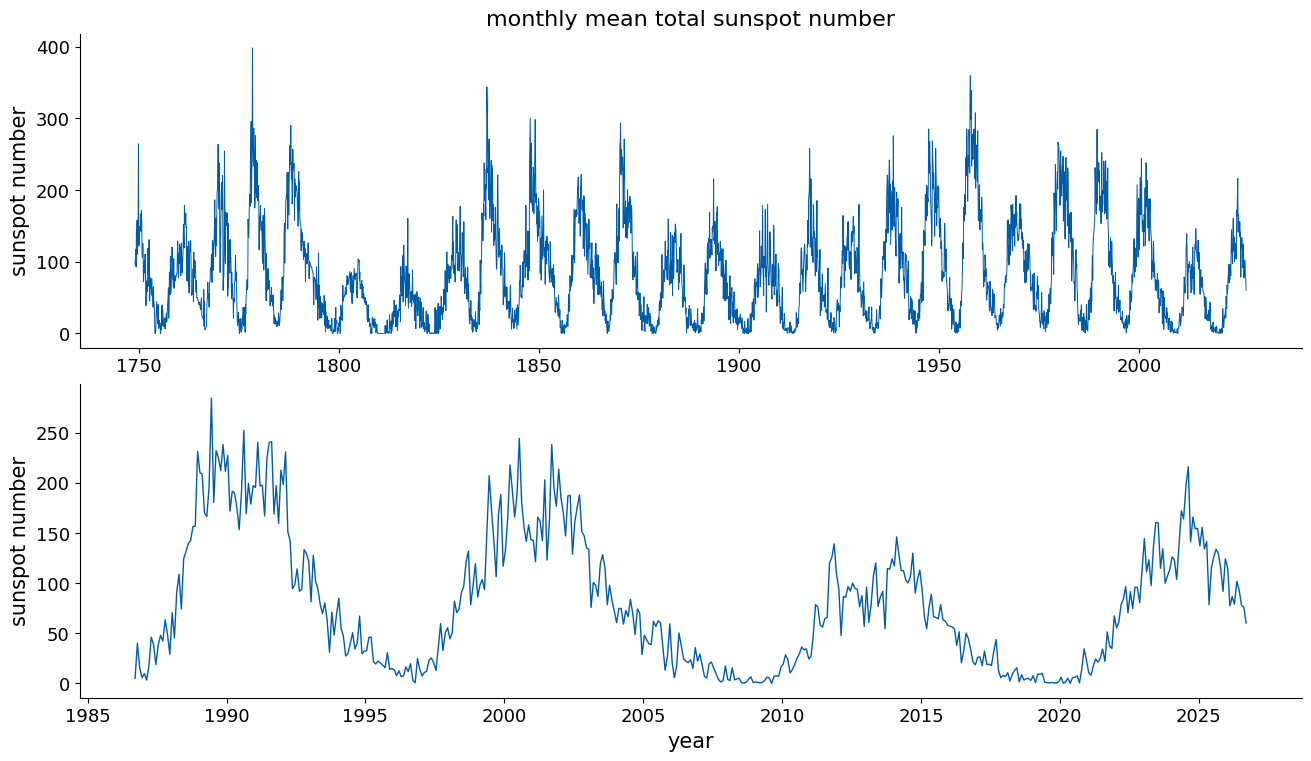

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(13, 7.5), layout="constrained")
axs[0].plot(t_sun, ssn, color=UJBlue, lw=0.7)
axs[0].set_ylabel("sunspot number"); axs[0].set_title("monthly mean total sunspot number")
sel = t_sun >= t_sun[-1] - 40
axs[1].plot(t_sun[sel], ssn[sel], color=UJBlue, lw=1)
axs[1].set_ylabel("sunspot number"); axs[1].set_xlabel("year")
plt.show()
print(f"mean {ssn.mean():.1f}, standard deviation {ssn.std():.1f}, median {np.median(ssn):.1f}, "
      f"min {ssn.min():.1f}, max {ssn.max():.1f} in {t_sun[ssn.argmax()]:.2f}")
print(f"months with a mean of zero: {int(np.sum(ssn == 0))}")

The record shows about 25 cycles. The monthly mean is 82.2 with the standard deviation 67.5 and the median 68.6, and it ranges from 0 to 398.2, a value reached in 1778. In 67 months not a single spot was seen. The heights of the maxima vary strongly from cycle to cycle, and around 1800 to 1830 several weak cycles follow each other. The zoom on the last forty years shows that the rise of a cycle is faster than its decline.

The histogram shows how the values are distributed. Its shape decides whether a mean squared error, which weights large deviations strongly, is a sensible loss, and whether the record has hard bounds or rare extreme values that a forecast has to handle. The skewness measures the asymmetry of the distribution, zero for a symmetric one.

skewness 0.91 (0 for a symmetric distribution)


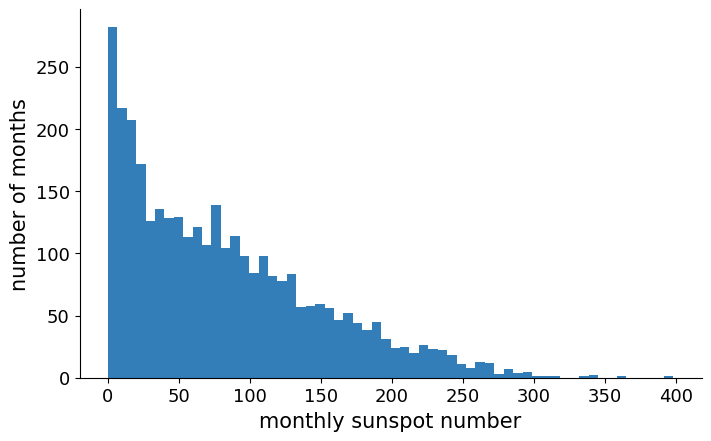

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.3), layout="constrained")
ax.hist(ssn, bins=60, color=UJBlue, alpha=0.8)
ax.set_xlabel("monthly sunspot number"); ax.set_ylabel("number of months")
plt.show()
print(f"skewness {scipy.stats.skew(ssn):.2f} (0 for a symmetric distribution)")

The distribution of the monthly values is bounded by zero and skewed to large values, with a skewness of 0.91. Months near the minimum, with few spots, are the most frequent, and very high values occur only at the peaks of strong cycles.

The autocorrelation function of equation (2) measures how long correlations persist in the record. Their duration sets the scale of the forecasts. Persistence reaches about $\rho(\tau)^2$ at the horizon τ, so the decay of ρ shows how fast the simplest forecast loses its skill, and an oscillation of ρ reveals a cycle that a model can continue.

correlation time (rho < 1/e): 25 months
rho at 1, 6, 12, 20 months: [0.918 0.832 0.724 0.495]
first minimum at 5.25 years (rho = -0.443), next maximum at 10.67 years (rho = 0.579)


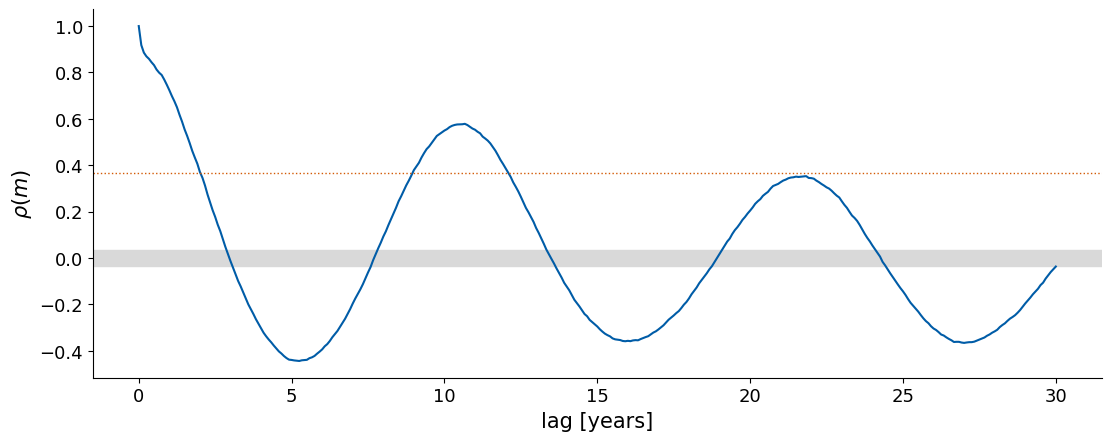

In [8]:
MAX_LAG = 12 * 30                                  # 30 years
rho = autocorrelation(ssn, MAX_LAG)
lags_years = np.arange(MAX_LAG + 1) * DT
fig, ax = plt.subplots(figsize=(11, 4.3), layout="constrained")
ax.plot(lags_years, rho, color=UJBlue)
ax.axhspan(-2 / np.sqrt(len(ssn)), 2 / np.sqrt(len(ssn)), color="0.85", zorder=0)
ax.axhline(np.exp(-1), color=DSOrange, ls=":", lw=1)
ax.set_xlabel("lag [years]"); ax.set_ylabel(r"$\rho(m)$")
plt.show()
first_min = np.argmin(rho[: 12 * 9])
second_max = 12 * 7 + np.argmax(rho[12 * 7: 12 * 16])
print(f"correlation time (rho < 1/e): {correlation_time(rho)} months")
print(f"rho at 1, 6, 12, 20 months: {np.round(rho[[1, 6, 12, 20]], 3)}")
print(f"first minimum at {first_min * DT:.2f} years (rho = {rho[first_min]:.3f}), "
      f"next maximum at {second_max * DT:.2f} years (rho = {rho[second_max]:.3f})")

The autocorrelation is 0.918 at one month, 0.832 at six months, 0.724 at one year and 0.495 at twenty months, and it falls below 1/e after 25 months. It then turns negative, with a minimum of −0.443 at 5.25 years, half a cycle, and rises to a second maximum of 0.579 at 10.67 years, one cycle. The oscillation of the autocorrelation shows the cycle, and the decay of its maxima shows that the cycles are irregular, so that the record gradually forgets its phase.

The power spectrum of equation (4) decomposes the variance of the record into periods. A sharp peak marks a cycle with a fixed period, a broad hump an irregular oscillation, and a flat spectrum a record without memory. We plot the raw periodogram and its Welch average on a logarithmic power axis.

record length 277.8 years, frequency resolution 0.0036 cycles per year
largest periodogram peak at f = 0.0900 per year, period 11.11 years
five largest peaks, periods in years: [11.11 10.68  9.92 92.58 11.57]
fraction of the variance at periods between 8 and 15 years: 0.64


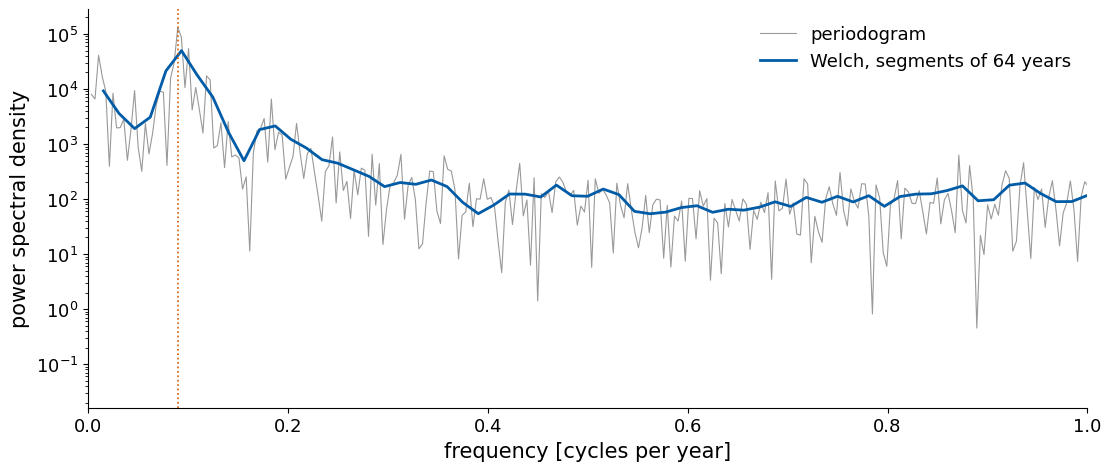

In [9]:
f, P = periodogram(ssn, DT)
f_w, P_w = scipy.signal.welch(ssn - ssn.mean(), fs=1 / DT, nperseg=12 * 64, scaling="density")
j_peak = 1 + np.argmax(P[1:])
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
ax.semilogy(f[1:], P[1:], color="0.6", lw=0.8, label="periodogram")
ax.semilogy(f_w[1:], P_w[1:] / 2, color=UJBlue, lw=2, label="Welch, segments of 64 years")
ax.axvline(f[j_peak], color=DSOrange, ls=":", lw=1.2)
ax.set_xlim(0, 1.0); ax.set_xlabel("frequency [cycles per year]"); ax.set_ylabel("power spectral density")
ax.legend()
plt.show()
print(f"record length {len(ssn) * DT:.1f} years, frequency resolution {1 / (len(ssn) * DT):.4f} cycles per year")
print(f"largest periodogram peak at f = {f[j_peak]:.4f} per year, period {1 / f[j_peak]:.2f} years")
top = np.argsort(P[1:])[::-1][:5] + 1
print("five largest peaks, periods in years:", np.round(1 / f[top], 2))
print(f"fraction of the variance at periods between 8 and 15 years: {P[(f > 1 / 15) & (f < 1 / 8)].sum() / P[1:].sum():.2f}")

The record covers 277.8 years, which gives the frequency resolution 0.0036 cycles per year. The largest peak of the periodogram lies at 0.0900 cycles per year, a period of 11.11 years, and the neighbouring large peaks at 10.68, 9.92 and 11.57 years show that the cycle has no single sharp period. Periods between 8 and 15 years carry 64% of the variance. A peak at 92.58 years points to a slow modulation of the height of the cycles over about a century, which the record covers only three times.

The delay plot draws each value against the value κ samples earlier. It represents both linear and nonlinear dependence between past and future through a two-dimensional delay embedding. We draw it for a short, an intermediate and a long delay.

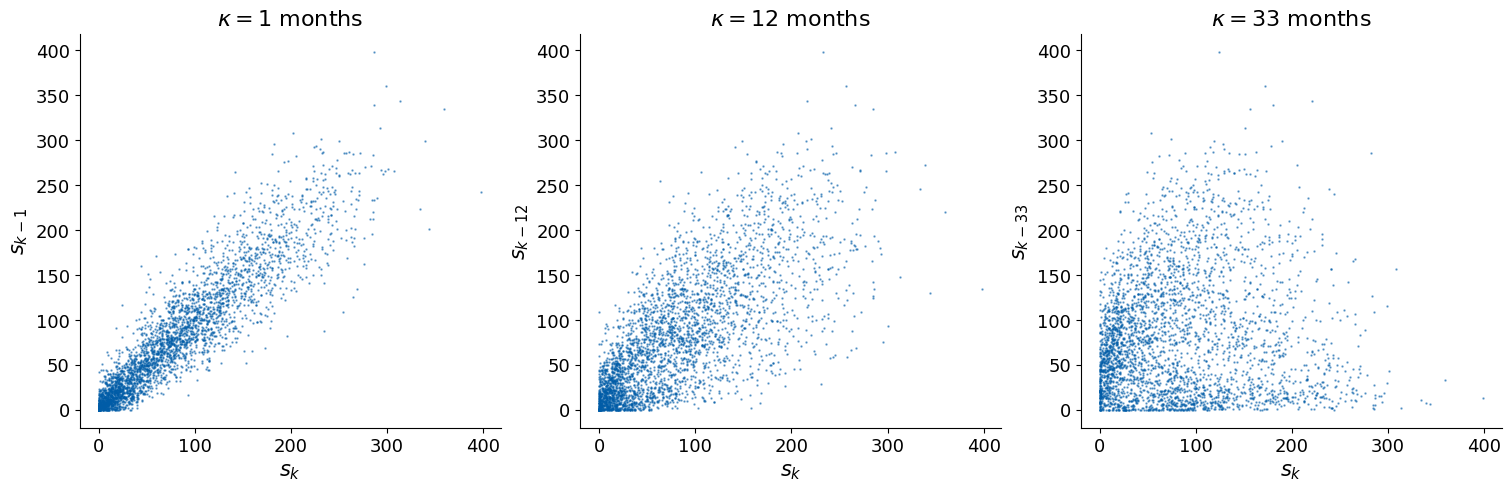

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
for ax, kappa in zip(axs, (1, 12, 33)):
    ax.plot(ssn[kappa:], ssn[:-kappa], ".", ms=1.5, alpha=0.5, color=UJBlue)
    ax.set_xlabel(r"$s_k$"); ax.set_ylabel(rf"$s_{{k-{kappa}}}$"); ax.set_title(rf"$\kappa = {kappa}$ months")
plt.show()

At κ = 1 month the points lie along the diagonal with a spread that grows with the sunspot number, so the month-to-month fluctuations are larger at the maximum of a cycle. At κ = 12 months the cloud is wider, and at κ = 33 months, about a quarter of a cycle, the points fill a broad region in which a value near zero can be followed by any value. A forecast from the last 20 months can follow the course of a cycle over a few months, while the phase and the height of the next maximum are only weakly fixed by the recent values.

### Delay embedding

The hidden state of a deterministic system can be reconstructed from one measured coordinate using the delay vector
$$\mathbf u_k=\big(s_k,\;s_{k-\kappa},\;\dots,\;s_{k-(m-1)\kappa}\big) , \tag{5}$$
built from m values of the record spaced by the delay κ. By the theorem of Takens, for a large enough embedding dimension m the cloud of delay vectors is a faithful picture of the attractor. Mutual information determines κ from the dependence between delayed values, and false nearest neighbours determine m from the geometry of the reconstructed record.

The delay κ is taken at the first local minimum of the mutual information between $s_k$ and $s_{k-\kappa}$ [A. M. Fraser, H. L. Swinney, Phys. Rev. A **33**, 1134 (1986), [doi:10.1103/PhysRevA.33.1134](https://doi.org/10.1103/PhysRevA.33.1134)]. The range of the record is divided into 16 bins of equal width. For a delay κ we count, over all pairs $(s_{k-\kappa},s_k)$, the fraction $p_{ij}(\kappa)$ of pairs whose first value falls into bin i and second value into bin j, and the fractions $p_i$ and $p_j$ of single values in each bin. The mutual information is
$$I(\kappa)=\sum_{i,j}p_{ij}(\kappa)\,\ln\frac{p_{ij}(\kappa)}{p_i\,p_j} , \tag{6}$$
measured in nats. It is zero when the two values are independent, since then $p_{ij}=p_ip_j$ and every logarithm vanishes, and it grows with the dependence of the two values, linear or nonlinear. The autocorrelation of equation (2) measures only the linear part of this dependence. At the first minimum of I(κ) a new delay coordinate adds the most new information while it still belongs to the same stretch of motion.

The embedding dimension m is found with false nearest neighbours [M. B. Kennel, R. Brown, H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. If m is too small, the picture of the attractor is folded onto itself and points from distant parts of the orbit appear as neighbours. For every delay vector $\mathbf u_i^{(m)}$ of dimension m we find its nearest neighbour $\mathbf u_j^{(m)}$, excluding the points with $|i-j|\le w$, which are close only because they are close in time. This exclusion is called the Theiler window. The pair is a false neighbour if the next delay coordinate separates the two points strongly,
$$\frac{\big|s_{i-m\kappa}-s_{j-m\kappa}\big|}{\big\|\mathbf u_i^{(m)}-\mathbf u_j^{(m)}\big\|}>R_{\rm tol}=15 . \tag{7}$$
The fraction of false neighbours is computed for m = 1, 2, …, and the embedding dimension is the smallest m at which it falls below 5%. The ratio test alone is unreliable at large m. The distance between nearest neighbours grows with m, because every added coordinate adds to it, and the ratio of equation (7) becomes small for any record, also for noise. Kennel and co-workers therefore add an absolute test. The pair is also counted as false if its distance in m + 1 dimensions exceeds twice the standard deviation $\sigma_s$ of the record,
$$\frac{\Big(\big\|\mathbf u_i^{(m)}-\mathbf u_j^{(m)}\big\|^2+\big|s_{i-m\kappa}-s_{j-m\kappa}\big|^2\Big)^{1/2}}{\sigma_s}>2 , \tag{8}$$
which identifies neighbours separated by a large distance relative to the variation in the record. We compute both fractions and choose the embedding dimension with the ratio test. The combined fraction, which counts a pair as false under either test, helps to tell a record from a low-dimensional deterministic law from a stochastic record. Its value depends on the record length, the measurement noise and the thresholds. For a low-dimensional deterministic law it stays near zero once the attractor is unfolded. For a stochastic record new random influences enter every coordinate, the nearest neighbours stay far apart in the sense of equation (8), and the combined fraction stays high and grows with m.

The embedding window has the length $(m-1)\kappa+1$ samples and can serve directly as the input of the AR model and of NVAR, with L = m values taken with the stride κ.

In [11]:
from scipy.spatial import cKDTree

def mutual_information(x, max_lag, bins=16):
    # equation (6) for kappa = 0..max_lag, from the same N - max_lag pairs for every delay
    edges = np.linspace(x.min(), x.max(), bins + 1)
    n = len(x) - max_lag
    out = []
    for lag in range(max_lag + 1):
        H, _, _ = np.histogram2d(x[:n], x[lag:lag + n], bins=[edges, edges])
        p = H / n
        pi, pj = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
        nz = p > 0
        out.append(np.sum(p[nz] * np.log(p[nz] / (pi * pj)[nz])))
    return np.array(out)

def first_local_min(c):
    for j in range(1, len(c) - 1):
        if c[j] < c[j - 1] and c[j] <= c[j + 1]:
            return j
    return None

def delay_matrix(x, m, kappa):
    # rows u_k = (x_k, x_(k-kappa), ..., x_(k-(m-1)kappa)) for k = (m-1)kappa .. N-1, equation (5)
    k0 = (m - 1) * kappa
    return np.stack([x[k0 - j * kappa:len(x) - j * kappa] for j in range(m)], axis=1)

def false_neighbour_fraction(x, kappa, m_max=8, w=10, r_tol=15.0, a_tol=2.0):
    # equations (7) and (8) for m = 1..m_max; nearest neighbours outside the Theiler window |i - j| <= w
    # returns the fraction of the ratio test and the fraction of the ratio test or the absolute test
    sigma = x.std()
    fractions, combined = [], []
    for m in range(1, m_max + 1):
        Y = delay_matrix(x, m + 1, kappa)            # first m columns: u^(m); last column: the next delay coordinate
        Ym, extra_col = Y[:, :m], Y[:, m]
        d, j = cKDTree(Ym).query(Ym, k=2 * w + 2)    # at most 2w + 1 points lie inside the window
        i = np.arange(len(Ym))[:, None]
        first = np.argmax(np.abs(j - i) > w, axis=1)
        jj, r = j[np.arange(len(Ym)), first], d[np.arange(len(Ym)), first]
        ok = r > 0                                   # identical vectors give no ratio
        extra = np.abs(extra_col[ok] - extra_col[jj[ok]])
        test_ratio = extra / r[ok] > r_tol
        test_abs = np.sqrt(r[ok] ** 2 + extra ** 2) / sigma > a_tol
        fractions.append(np.mean(test_ratio))
        combined.append(np.mean(test_ratio | test_abs))
    return np.array(fractions), np.array(combined)

def embedding_dimension(fractions, threshold=0.05):
    below = np.flatnonzero(fractions < threshold)
    return int(below[0]) + 1 if below.size else None

first minimum of the mutual information at kappa = 34 samples = 2.83 years, I(0) = 2.169 nats, I(kappa) = 0.088 nats
false-neighbour fractions for m = 1..8 with kappa = 34 and Theiler window 25
  ratio test            [0.968 0.614 0.159 0.018 0.002 0.    0.    0.   ]
  ratio or absolute test [0.968 0.614 0.171 0.067 0.064 0.074 0.087 0.093]
embedding dimension (fraction below 5%): 4, window length (m - 1) kappa + 1 = 103 samples


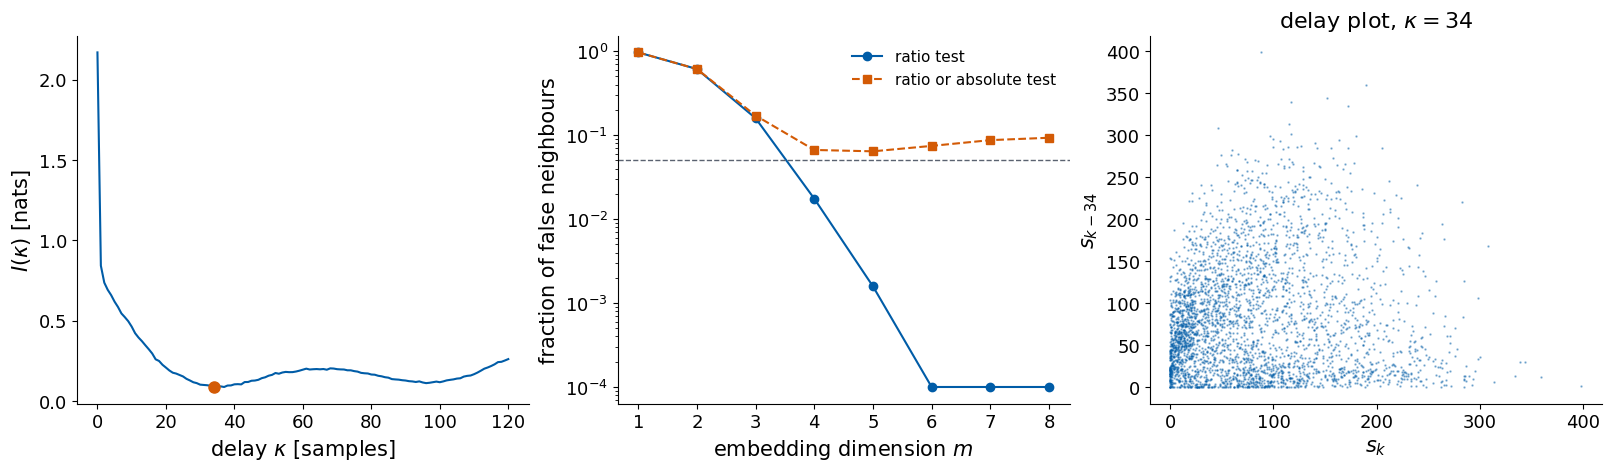

In [12]:
MI = mutual_information(ssn, 120)
KAPPA = first_local_min(MI)
FNN, FNN_BOTH = false_neighbour_fraction(ssn, KAPPA, m_max=8, w=25)
M_EMB = embedding_dimension(FNN)
print(f"first minimum of the mutual information at kappa = {KAPPA} samples = {KAPPA * 1 / 12:.3g} years, "
      f"I(0) = {MI[0]:.3f} nats, I(kappa) = {MI[KAPPA]:.3f} nats")
print(f"false-neighbour fractions for m = 1..8 with kappa = {KAPPA} and Theiler window 25")
print(f"  ratio test            {np.round(FNN, 3)}")
print(f"  ratio or absolute test {np.round(FNN_BOTH, 3)}")
print(f"embedding dimension (fraction below 5%): {M_EMB}"
      + (f", window length (m - 1) kappa + 1 = {(M_EMB - 1) * KAPPA + 1} samples" if M_EMB else ""))
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
axs[0].plot(np.arange(len(MI)), MI, color=UJBlue)
axs[0].plot(KAPPA, MI[KAPPA], "o", color=DSOrange, ms=8)
axs[0].set_xlabel(r"delay $\kappa$ [samples]"); axs[0].set_ylabel(r"$I(\kappa)$ [nats]")
axs[1].semilogy(np.arange(1, 9), np.maximum(FNN, 1e-4), "o-", color=UJBlue, label="ratio test")
axs[1].semilogy(np.arange(1, 9), np.maximum(FNN_BOTH, 1e-4), "s--", color=DSOrange, label="ratio or absolute test")
axs[1].legend(fontsize=11)
axs[1].axhline(0.05, color=UJGray, ls="--", lw=1)
axs[1].set_xlabel("embedding dimension $m$"); axs[1].set_ylabel("fraction of false neighbours")
axs[2].plot(ssn[KAPPA:], ssn[:-KAPPA], ".", ms=1.5, alpha=0.4, color=UJBlue)
axs[2].set_xlabel(r"$s_k$"); axs[2].set_ylabel(rf"$s_{{k-{KAPPA}}}$"); axs[2].set_title(rf"delay plot, $\kappa = {KAPPA}$")
plt.show()

The following diagnostics describe the full available record, including the later test period. The predictive comparison below recomputes its delay and coordinate count from the fitting block only.

The mutual information falls from 2.169 nats at κ = 0 to 0.088 nats at its first minimum, κ = 34 months, 2.83 years, about a quarter of the solar cycle. A delay of a quarter period is the classical choice for an oscillation, since the two coordinates then behave like a sine and a cosine. The ratio test falls below 5% at m = 4, with 0.018, which gives the embedding window of (4 − 1)·34 + 1 = 103 months, almost a full cycle. The combined test stays between 0.064 and 0.093 for m = 4 to 8. A low-dimensional deterministic law keeps the combined fraction near zero once its attractor is unfolded, while for a stochastic record it stays high and grows with m, as for the temperature anomaly of central England, 0.17 to 0.25. The sunspot record has a strong deterministic component, the cycle, together with irregularities that the window of four values does not resolve.

In [13]:
SERIES = ssn          # the record that the forecasting protocol below splits into blocks

<hr/>
## 4. Forecasting protocol and scores

The record of length N is split in time order into a fitting block, the first 60% of the samples, a validation block, the next 20%, and a test block, the last 20%. A model is fitted on the fitting block, its settings are chosen by the score on the validation block, and AR, NVAR, MA, ARMA and MLP are then refitted on the fitting and validation blocks together before testing. The RNN and LSTM keep the checkpoint with the best validation score from their training on the fitting block. The record is standardised with the mean and the standard deviation of its fitting block. The split follows the time order because a forecast is always made from the past into the future. A random split would put neighbouring, strongly correlated values into the fitting and the test blocks, and the test score would measure how well a model interpolates between known values. Settings chosen on the test block would make its score optimistic, and a separate validation block is therefore used to choose them.

From every origin k the models receive the values up to $s_k$, at most the last L = 20 of them, and forecast $\hat s_{k+\tau}$ for the horizons τ = 1, …, 20, in months. The score at horizon τ is the forecast capacity, the squared Pearson correlation between forecasts and targets over all test origins,
$$C(\tau)=r(\tau)^2,\qquad r(\tau)=\frac{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_\tau\big)\big(s_{k+\tau}-\overline s_\tau\big)}{\sqrt{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_\tau\big)^2\,\sum_k\big(s_{k+\tau}-\overline s_\tau\big)^2}} , \tag{9}$$
where the bars are averages over the origins at fixed τ. C(τ) is the fraction of the variance of the targets explained by a straight-line fit on the forecasts. It is 1 when the forecasts lie on any straight line against the targets and 0 when they are uncorrelated. The total capacity
$$C_{\rm tot}=\sum_{\tau=1}^{20}C(\tau) \tag{10}$$
has the maximum 20. A forecast without skill still gives C(τ) of about 1/n for n test origins.

Every model is compared with persistence, the forecast that the record keeps its last value,
$$\hat s_{k+\tau}=s_k\quad\text{for every }\tau . \tag{11}$$
Persistence needs no fitting and uses only the newest value. Its capacity follows from the autocorrelation function of equation (2). The correlation between $s_k$ and $s_{k+\tau}$ over the test origins is close to the autocorrelation ρ(τ) of the record at the lag τ, so persistence reaches $C(\tau)\approx\rho(\tau)^2$. A model is useful only where it beats persistence, and the gain over persistence measures what the model has learned beyond the memory of the last value.

In [14]:
TAU_MAX, L_MAX = 20, 20
TAUS = np.arange(1, TAU_MAX + 1)
N = len(SERIES)                                    # length of the record used for forecasting
N_FIT, N_VAL = int(0.6 * N), int(0.2 * N)
K0 = L_MAX - 1                                     # first origin with a full window of L_MAX values
O_FIT = np.arange(K0, N_FIT - TAU_MAX)             # origins whose targets lie in the fitting block
O_VAL = np.arange(N_FIT, N_FIT + N_VAL - TAU_MAX)  # ... in the validation block
O_TRAIN = np.arange(K0, N_FIT + N_VAL - TAU_MAX)   # ... in fitting and validation blocks (final fit)
O_TEST = np.arange(N_FIT + N_VAL, N - TAU_MAX)     # ... in the test block
print(f"N = {N}: fitting block 0..{N_FIT - 1}, validation {N_FIT}..{N_FIT + N_VAL - 1}, test {N_FIT + N_VAL}..{N - 1}")
print(f"origins: fit {len(O_FIT)}, validation {len(O_VAL)}, train {len(O_TRAIN)}, test {len(O_TEST)}")
print(f"no-skill floor: 1/n = {1 / len(O_TEST):.4f} per horizon, {TAU_MAX / len(O_TEST):.3f} for C_tot")

def standardise(x):
    # mean and standard deviation of the fitting block only
    return (x - x[:N_FIT].mean()) / x[:N_FIT].std()

def windows(s, origins, L):
    # rows (s_k, s_(k-1), ..., s_(k-L+1)), newest value first; shape (len(origins), L)
    return s[np.asarray(origins)[:, None] - np.arange(L)[None, :]]

def targets(s, origins):
    # Y[i, tau-1] = s_(k_i + tau); shape (len(origins), TAU_MAX)
    return s[np.asarray(origins)[:, None] + TAUS[None, :]]

def capacity(P, Y):
    # C(tau) of equation (15) for every column; a constant forecast has r = 0
    Pc, Yc = P - P.mean(0), Y - Y.mean(0)
    den = np.sqrt((Pc ** 2).sum(0) * (Yc ** 2).sum(0))
    r = np.where(den > 0, (Pc * Yc).sum(0) / np.where(den > 0, den, 1.0), 0.0)
    return r ** 2

# check of capacity against scipy on random numbers
_P, _Y = np.random.default_rng(0).standard_normal((2, 300, 3))
assert np.allclose(capacity(_P, _Y), [scipy.stats.pearsonr(_P[:, j], _Y[:, j]).statistic ** 2 for j in range(3)])

N = 3333: fitting block 0..1998, validation 1999..2664, test 2665..3332
origins: fit 1960, validation 646, train 2626, test 648
no-skill floor: 1/n = 0.0015 per horizon, 0.031 for C_tot


We divide the record in time order into fitting, validation and test blocks. At an origin k, the model receives a window of the last L values and forecasts the value τ steps later. The input window is marked in blue and the target in orange. We repeat the forecast at every origin of a block and compare the predictions with the measured values.

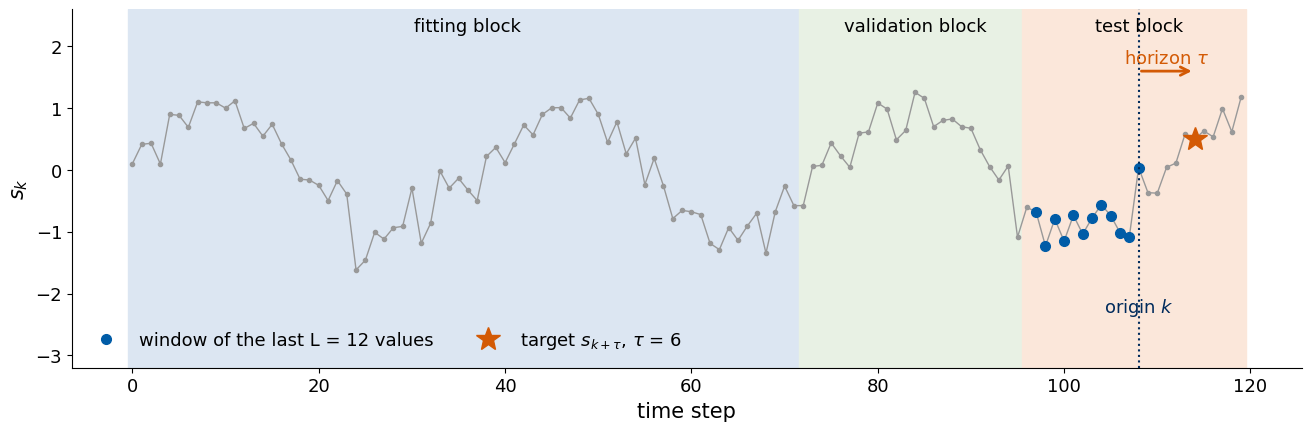

In [15]:
# sketch of the forecasting task: blocks, window of past values, forecast at the horizon tau
rng = np.random.default_rng(1)
t = np.arange(120)
x = np.sin(2 * np.pi * t / 37) + 0.3 * rng.standard_normal(120)
k, L_demo, tau_demo = 108, 12, 6
fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
for (a, b), name, col in (((0, 72), "fitting block", "#DCE6F2"), ((72, 96), "validation block", "#E8F1E4"),
                          ((96, 120), "test block", "#FBE7DA")):
    ax.axvspan(a - 0.5, b - 0.5, color=col, zorder=0)
    ax.text((a + b) / 2, 2.25, name, ha="center", fontsize=13)
ax.plot(t, x, "o-", color="0.6", ms=3, lw=1)
win = np.arange(k - L_demo + 1, k + 1)
ax.plot(win, x[win], "o", color=UJBlue, ms=7, label=f"window of the last L = {L_demo} values")
ax.plot(k + tau_demo, x[k + tau_demo], "*", color=DSOrange, ms=18, label=rf"target $s_{{k+\tau}}$, $\tau$ = {tau_demo}")
ax.annotate("", xy=(k + tau_demo, 1.6), xytext=(k, 1.6), arrowprops=dict(arrowstyle="->", lw=2, color=DSOrange))
ax.text(k + tau_demo / 2, 1.72, r"horizon $\tau$", ha="center", color=DSOrange, fontsize=13)
ax.axvline(k, color=UJNavy, ls=":", lw=1.5); ax.text(k, -2.3, "origin $k$", ha="center", color=UJNavy, fontsize=13)
ax.set_ylim(-3.2, 2.6); ax.set_xlabel("time step"); ax.set_ylabel("$s_k$"); ax.legend(loc="lower left", ncol=2)
plt.show()

For each signal, `plot_scatter` draws the forecasts of every model against the targets at the horizons τ = 1, 5 and 20, one row per model, with the diagonal $\hat s=s$ and the value of C(τ) in each panel. `plot_capacity` draws C(τ) of all models against τ, and `ctot_table` prints the total capacities.

In [16]:
MODEL_COLORS = {"persistence": UJGray, "AR": UJBlue, "MA": "#7FB3E0", "ARMA": UJNavy, "NVAR": "#2A9D8F",
                "MLP": "#E9C46A", "RNN": "#B5651D", "LSTM": DSOrange}

def plot_scatter(name, preds, s, taus=(1, 5, 20)):
    Y = targets(s, O_TEST)
    models = list(preds)
    fig, axs = plt.subplots(len(models), len(taus), figsize=(3.4 * len(taus), 3.0 * len(models)),
                            layout="constrained", squeeze=False)
    lim = np.quantile(np.abs(Y), 0.995) * 1.1
    for i, m in enumerate(models):
        C = capacity(preds[m], Y)
        for j, t in enumerate(taus):
            ax = axs[i, j]
            ax.plot(Y[:, t - 1], preds[m][:, t - 1], ".", ms=3, alpha=0.5, color=MODEL_COLORS.get(m, UJBlue))
            ax.plot([-lim, lim], [-lim, lim], color="0.5", lw=0.8, ls="--")
            ax.set_xlim(-lim, lim)
            ax.text(0.04, 0.96, f"$C={C[t - 1]:.3f}$", transform=ax.transAxes, va="top", fontsize=12)
            if i == 0: ax.set_title(rf"$\tau={t}$")
            if i == len(models) - 1: ax.set_xlabel(r"true $s_{k+\tau}$")
            if j == 0: ax.set_ylabel(f"{m}\n" + r"forecast $\hat s_{k+\tau}$")
    fig.suptitle(name)
    plt.show()

def plot_capacity(results, names, theory=None, ylim=None):
    fig, axs = plt.subplots(1, len(names), figsize=(6.2 * len(names), 4.6), layout="constrained", squeeze=False)
    for ax, name in zip(axs[0], names):
        for m, C in results[name].items():
            ax.plot(TAUS, C, "o-", ms=4, color=MODEL_COLORS.get(m, UJBlue), label=m)
        if theory is not None and name in theory:
            ax.plot(TAUS, theory[name], "k--", lw=1.5, label="theory")
        ax.axhline(1 / len(O_TEST), color="0.6", lw=1, ls=":")
        ax.set_title(name); ax.set_xlabel(r"horizon $\tau$")
        if ylim: ax.set_ylim(*ylim)
    axs[0, 0].set_ylabel(r"$C(\tau)$"); axs[0, -1].legend(fontsize=11, loc="upper right")
    plt.show()

def ctot_table(results):
    tab = pd.DataFrame({name: {m: C.sum() for m, C in res.items()} for name, res in results.items()})
    print("total capacity C_tot = sum of C(tau) over tau = 1..20 (maximum 20)")
    print(tab.round(3).to_string(na_rep="-"))
    return tab

<hr/>
## 5. Models

The models form a sequence of increasing flexibility. Persistence uses only the last value. AR, MA and ARMA are linear in the past values or past errors. NVAR adds products of past values and is still fitted by linear least squares. The MLP learns its own nonlinear features of the window, and the RNN and the LSTM carry a hidden state through the window. Comparing them on the same record shows how much of the future is fixed by linear memory alone and how much more a nonlinear model can extract.

Every model is a function that receives a standardised signal s and returns the forecasts for all test origins and all horizons, an array of shape (number of test origins, 20). Persistence forecasts every horizon by the last value $s_k$. The other seven models use the implementations developed in the lecture notebooks.

1. **AR**, the direct autoregressive model. For every horizon τ a linear readout of the window $(s_k,\dots,s_{k-L+1})$ plus an offset, fitted by ridge regression, all horizons at once as the columns of one target matrix. We choose L from {1, 2, 3, 5, 10, 20} and the ridge strength λ from {10⁻⁶, 10⁻², 1, 100} by $C_{\rm tot}$ on the validation block.
2. **MA**, the moving-average model MA(q), fitted by maximum likelihood with `statsmodels` (`ARIMA` with order (0, 0, q) and a constant). The τ-step forecast iterates the one-step model with the future errors set to zero. The past errors $e_k$ are the residuals of the fitted model on the whole record (`res.apply(s).resid`). We choose q from {1, 2, 3, 5} on the validation block.
3. **ARMA**, the model ARMA(p, q), fitted and iterated in the same way, with (p, q) from {(1, 1), (2, 1), (1, 2), (2, 2)}.
4. **NVAR**, the window of L values with stride κ, every κ-th value, together with all products of two of its entries, and a ridge readout per horizon. We choose L from {2, 3, 5, 8}, κ from {1, 2, 4} and λ as for AR.
5. **MLP**, `sklearn.neural_network.MLPRegressor` with tanh units on the window of the last 20 values, with 20 outputs, one per horizon. We choose one hidden layer of 32 or 64 units and the weight penalty `alpha` from {10⁻³, 10⁻¹, 1} on the validation block, with `early_stopping=True` and `random_state=0`.
6. **RNN**, an Elman recurrent network with 32 hidden units, run over the window of the last 20 values from the oldest to the newest, with a linear readout of the last hidden state to the 20 horizons. We train it with Adam on the mean squared error of the fitting block, with gradient clipping and early stopping on the validation loss.
7. **LSTM**, the same with an LSTM cell.

The direct AR model and NVAR both fit their readouts by ridge regression. For a feature matrix Φ with one row per origin and a target matrix Y with one column per horizon, the ridge loss is
$$\mathcal L(W,\mathbf b)=\big\|Y-\Phi W-\mathbf 1\mathbf b^\top\big\|^2+\lambda\|W\|^2 , \tag{12}$$
where $\mathbf 1$ is a column of ones and $\mathbf b$ the offsets of the horizons. Its minimum follows from the centred matrices $\Phi_c$ and $Y_c$, from which the column means are subtracted,
$$W=(\Phi_c^\top\Phi_c+\lambda I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b^\top=\overline Y-\overline\Phi\,W , \tag{13}$$
where the bars are the column means, so the offsets are not penalised.

The MA and ARMA models are fitted by maximum likelihood, since their past errors depend on the parameters themselves. With the statsmodels convention, the fitted ARMA(p, q) model reads
$$s_k-\mu=\sum_{i=1}^p\phi_i\,(s_{k-i}-\mu)+e_k+\sum_{j=1}^q\theta_j\,e_{k-j} , \tag{14}$$
where μ is the mean of the process and $e_k$ the one-step error. The τ-step forecast applies equation (14) repeatedly from the origin k, with the forecasts in place of the unknown future values and zero in place of the unknown future errors. An MA(q) forecast therefore returns to μ after q steps.

The functions receive only the record. They use the origins `O_FIT`, `O_VAL`, `O_TRAIN` and `O_TEST` and the functions `windows`, `targets` and `capacity` of Section 4.

In [17]:
CHOSEN = {}          # settings chosen on the validation block, filled in by the forecasters

def forecast_persistence(s):
    # s_(k+tau) is forecast by s_k for every horizon
    return np.repeat(s[O_TEST][:, None], TAU_MAX, axis=1)

In [18]:
def ridge_fit(X, Y, lam):
    # equation (13): ridge regression with an unpenalised offset
    mx, my = X.mean(0), Y.mean(0)
    Xc, Yc = X - mx, Y - my
    W = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ Yc)
    return W, my - mx @ W

def ar_features(s, origins, L, stride=1):
    return s[np.asarray(origins)[:, None] - stride * np.arange(L)[None, :]]

def nvar_features(s, origins, L, stride=1):
    U = ar_features(s, origins, L, stride)
    i, j = np.triu_indices(L)                        # all products u_i u_j with i <= j
    return np.concatenate([U, U[:, i] * U[:, j]], axis=1)

LAMS = [1e-6, 1e-2, 1.0, 100.0]

def direct_ridge(s, feature_fn, grid, label):
    best = None
    for hp in grid:
        for lam in LAMS:
            W, b = ridge_fit(feature_fn(s, O_FIT, *hp), targets(s, O_FIT), lam)
            ct = capacity(feature_fn(s, O_VAL, *hp) @ W + b, targets(s, O_VAL)).sum()
            if best is None or ct > best[0]:
                best = (ct, hp, lam)
    _, hp, lam = best
    W, b = ridge_fit(feature_fn(s, O_TRAIN, *hp), targets(s, O_TRAIN), lam)
    CHOSEN[label] = dict(hp=hp, lam=lam)
    return feature_fn(s, O_TEST, *hp) @ W + b

def forecast_ar(s):
    return direct_ridge(s, ar_features, [(L, 1) for L in (1, 2, 3, 5, 10, 20)], "AR")

def forecast_nvar(s):
    grid = [(L, st) for L in (2, 3, 5, 8) for st in (1, 2, 4) if (L - 1) * st <= K0]
    return direct_ridge(s, nvar_features, grid, "NVAR")

# check of ridge_fit against scikit-learn
from sklearn.linear_model import Ridge
_X, _Y = np.random.default_rng(1).standard_normal((200, 6)), np.random.default_rng(2).standard_normal((200, 3))
_W, _b = ridge_fit(_X, _Y, 0.5)
_sk = Ridge(alpha=0.5).fit(_X, _Y)
print(f"max |ridge_fit - sklearn Ridge| = {max(np.abs(_W - _sk.coef_.T).max(), np.abs(_b - _sk.intercept_).max()):.1e}")

max |ridge_fit - sklearn Ridge| = 4.2e-17


In [19]:
def arma_rollout(s, res, p, q, origins):
    par = dict(zip(res.model.param_names, res.params))
    mu = par["const"]
    phi = np.array([par[f"ar.L{i}"] for i in range(1, p + 1)])
    theta = np.array([par[f"ma.L{j}"] for j in range(1, q + 1)])
    e = res.apply(s).resid                           # one-step errors on the whole record, fitted parameters
    P = np.empty((len(origins), TAU_MAX))
    for n, k in enumerate(origins):
        x = list(s[k - p + 1:k + 1] - mu) if p else []
        ee = list(e[k - q + 1:k + 1]) if q else []
        for t in range(TAU_MAX):
            x_new = sum(phi[i] * x[-1 - i] for i in range(p)) + sum(theta[j] * ee[-1 - j] for j in range(q))
            x.append(x_new); ee.append(0.0)          # future errors are set to zero
            P[n, t] = x_new + mu
    return P, e

def arma_select(s, orders, label):
    best = None
    for (p, q) in orders:
        res = ARIMA(s[:N_FIT], order=(p, 0, q), trend="c").fit()
        ct = capacity(arma_rollout(s, res, p, q, O_VAL)[0], targets(s, O_VAL)).sum()
        if best is None or ct > best[0]:
            best = (ct, (p, q))
    p, q = best[1]
    res = ARIMA(s[:N_FIT + N_VAL], order=(p, 0, q), trend="c").fit()
    CHOSEN[label] = dict(order=(p, q))
    return arma_rollout(s, res, p, q, O_TEST)[0], res

def forecast_ma(s):
    return arma_select(s, [(0, q) for q in (1, 2, 3, 5)], "MA")[0]

def forecast_arma(s):
    return arma_select(s, [(1, 1), (2, 1), (1, 2), (2, 2)], "ARMA")[0]

The MLP is the `MLPRegressor` of scikit-learn with one hidden layer of tanh units. It receives the window of the last 20 values and returns 20 outputs, one per horizon, and it is trained on the mean squared error with a weight penalty `alpha`. With `early_stopping=True` it keeps 10% of the fitting data aside and stops when the error on them no longer decreases.

For early stopping scikit-learn holds out a random subset of the fitting windows. The architecture is selected on the chronological validation block, and the forecasts are scored on the later test block.

In [20]:
def forecast_mlp(s):
    best = None
    for width in (32, 64):
        for alpha in (1e-3, 1e-1, 1.0):
            m = MLPRegressor((width,), activation="tanh", alpha=alpha, max_iter=400, early_stopping=True,
                             random_state=0).fit(windows(s, O_FIT, L_MAX), targets(s, O_FIT))
            ct = capacity(m.predict(windows(s, O_VAL, L_MAX)), targets(s, O_VAL)).sum()
            if best is None or ct > best[0]:
                best = (ct, width, alpha)
    _, width, alpha = best
    m = MLPRegressor((width,), activation="tanh", alpha=alpha, max_iter=400, early_stopping=True,
                     random_state=0).fit(windows(s, O_TRAIN, L_MAX), targets(s, O_TRAIN))
    CHOSEN["MLP"] = dict(width=width, alpha=alpha)
    return m.predict(windows(s, O_TEST, L_MAX))

The two recurrent networks read the window of 20 values one value at a time, from the oldest to the newest. The Elman cell updates a hidden state of 32 numbers with one tanh layer that receives the new value and the previous hidden state. The LSTM cell adds a cell state and four gates that decide what is kept, what is written and what is shown. After the last value a linear readout maps the hidden state to the 20 forecasts. Both are trained with the Adam optimiser on the mean squared error of the fitting block, the gradient norm is clipped at 1, and training stops when the error on the validation block has not improved for 20 passes over the data, keeping the best parameters.

In [21]:
orthogonal = nnx.initializers.orthogonal()

class RNNCell(nnx.Module):
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.Wx = nnx.Linear(n_x, n_h, rngs=rngs)
        self.Wh = nnx.Linear(n_h, n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, s):
        h = jnp.tanh(self.Wx(s) + self.Wh(h))
        return h, h

class LSTMCell(nnx.Module):
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.W = nnx.Linear(n_h + n_x, 4 * n_h, rngs=rngs)                         # blocks (i, f, g, o)
        self.W.bias[...] = self.W.bias[...].at[n_h:2 * n_h].set(1.0)              # forget bias 1
    def init_carry(self, B, dtype):
        return (jnp.zeros((B, self.n_h), dtype), jnp.zeros((B, self.n_h), dtype))
    def __call__(self, carry, s):
        c, h = carry
        a_i, a_f, a_g, a_o = jnp.split(self.W(jnp.concatenate([h, s], axis=-1)), 4, axis=-1)
        c = jax.nn.sigmoid(a_f) * c + jax.nn.sigmoid(a_i) * jnp.tanh(a_g)
        h = jax.nn.sigmoid(a_o) * jnp.tanh(c)
        return (c, h), h

class Recurrent(nnx.Module):
    def __init__(self, cell, n_h, n_out, *, rngs):
        self.cell = cell
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)
    def __call__(self, V):                                                       # V: (B, L, 1), oldest value first
        carry = self.cell.init_carry(V.shape[0], V.dtype)
        _, hs = jax.lax.scan(lambda c, x: self.cell(c, x), carry, jnp.swapaxes(V, 0, 1))
        return self.head(hs[-1])

def fit_recurrent(kind, s, n_h=32, seed=0, epochs=200, patience=20, lr=3e-3, batch=64):
    def data(origins):
        U = windows(s, origins, L_MAX)[:, ::-1, None]                            # oldest value first
        return jnp.asarray(U, jnp.float32), jnp.asarray(targets(s, origins), jnp.float32)
    (Uf, Yf), (Uv, Yv), (Ut, _) = data(O_FIT), data(O_VAL), data(O_TEST)
    rngs = nnx.Rngs(seed)
    model = Recurrent({"RNN": RNNCell, "LSTM": LSTMCell}[kind](1, n_h, rngs=rngs), n_h, TAU_MAX, rngs=rngs)
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(1.0), optax.adam(lr))
    opt_state = tx.init(params)
    loss_fn = lambda p, U, Y: jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)
    n_batches = Uf.shape[0] // batch

    @jax.jit
    def epoch(p, opt_state, key):
        idx = jax.random.permutation(key, Uf.shape[0])[:n_batches * batch].reshape(n_batches, batch)
        def step(carry, ib):
            p, opt_state = carry
            g = jax.grad(loss_fn)(p, Uf[ib], Yf[ib])
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), None
        (p, opt_state), _ = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, loss_fn(p, Uv, Yv)

    key, best = jax.random.key(seed), (np.inf, params, 0)
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_val = epoch(params, opt_state, sub)
        if float(l_val) < best[0]:
            best = (float(l_val), params, ep)
        elif ep - best[2] >= patience:
            break
    CHOSEN[kind] = dict(best_epoch=best[2] + 1, epochs_run=ep + 1)
    return np.asarray(nnx.merge(graphdef, best[1], rest)(Ut), np.float64)

def forecast_rnn(s):
    return fit_recurrent("RNN", s)

def forecast_lstm(s):
    return fit_recurrent("LSTM", s)

The function `run_models` applies every implemented model to a standardised record, scores the forecasts with equation (9), stores the capacities and the forecasts, and prints the settings chosen on the validation block.

In [22]:
FORECASTERS = {"persistence": forecast_persistence, "AR": forecast_ar, "MA": forecast_ma, "ARMA": forecast_arma,
               "NVAR": forecast_nvar, "MLP": forecast_mlp, "RNN": forecast_rnn, "LSTM": forecast_lstm}
RESULTS, PREDS, CHOSEN_BY_SERIES = {}, {}, {}

def run_models(name, s, models=tuple(FORECASTERS)):
    # runs every implemented model on the standardised signal s; unimplemented ones are skipped
    RESULTS[name], PREDS[name], CHOSEN_BY_SERIES[name] = {}, {}, {}
    Y = targets(s, O_TEST)
    for m in models:
        t0 = time.time()
        try:
            P = FORECASTERS[m](s)
        except NotImplementedError:
            continue
        PREDS[name][m], RESULTS[name][m] = P, capacity(P, Y)
        CHOSEN_BY_SERIES[name][m] = dict(CHOSEN.get(m, {}))
        info = CHOSEN.get(m, "")
        print(f"{name:14s} {m:12s} C_tot {RESULTS[name][m].sum():7.3f}   C(1) {RESULTS[name][m][0]:.3f}   "
              f"{info}  ({time.time() - t0:.1f} s)")

<hr/>
## 6. Forecasts of the sunspot number

We fit all eight models to the standardised record and score them on the test block. The scatter plots show, for every model, the forecasts against the true values at 1, 5 and 20 months, so that systematic errors such as forecasts that are too flat or that miss the maxima become visible. The curves C(τ) show how fast each model loses its skill with the horizon, and the table of total capacities ranks the models by one number. Persistence is the reference that every model has to beat.

In [23]:
s_sun = standardise(ssn)
print(f"test block: {t_sun[N_FIT + N_VAL]:.2f} to {t_sun[-1]:.2f}")
run_models("sunspots", s_sun)

test block: 1971.12 to 2026.70
sunspots       persistence  C_tot  11.740   C(1) 0.872     (0.0 s)
sunspots       AR           C_tot  14.461   C(1) 0.893   {'hp': (20, 1), 'lam': 1e-06}  (0.0 s)
sunspots       MA           C_tot   3.032   C(1) 0.849   {'order': (0, 5)}  (7.1 s)
sunspots       ARMA         C_tot  11.811   C(1) 0.887   {'order': (1, 1)}  (8.1 s)
sunspots       NVAR         C_tot  14.636   C(1) 0.882   {'hp': (5, 4), 'lam': 1e-06}  (0.1 s)
sunspots       MLP          C_tot  15.364   C(1) 0.891   {'width': 64, 'alpha': 1.0}  (5.2 s)
sunspots       RNN          C_tot  15.179   C(1) 0.880   {'best_epoch': 34, 'epochs_run': 54}  (6.0 s)
sunspots       LSTM         C_tot  15.287   C(1) 0.880   {'best_epoch': 19, 'epochs_run': 39}  (6.2 s)


total capacity C_tot = sum of C(tau) over tau = 1..20 (maximum 20)
             sunspots
persistence    11.740
AR             14.461
MA              3.032
ARMA           11.811
NVAR           14.636
MLP            15.364
RNN            15.179
LSTM           15.287


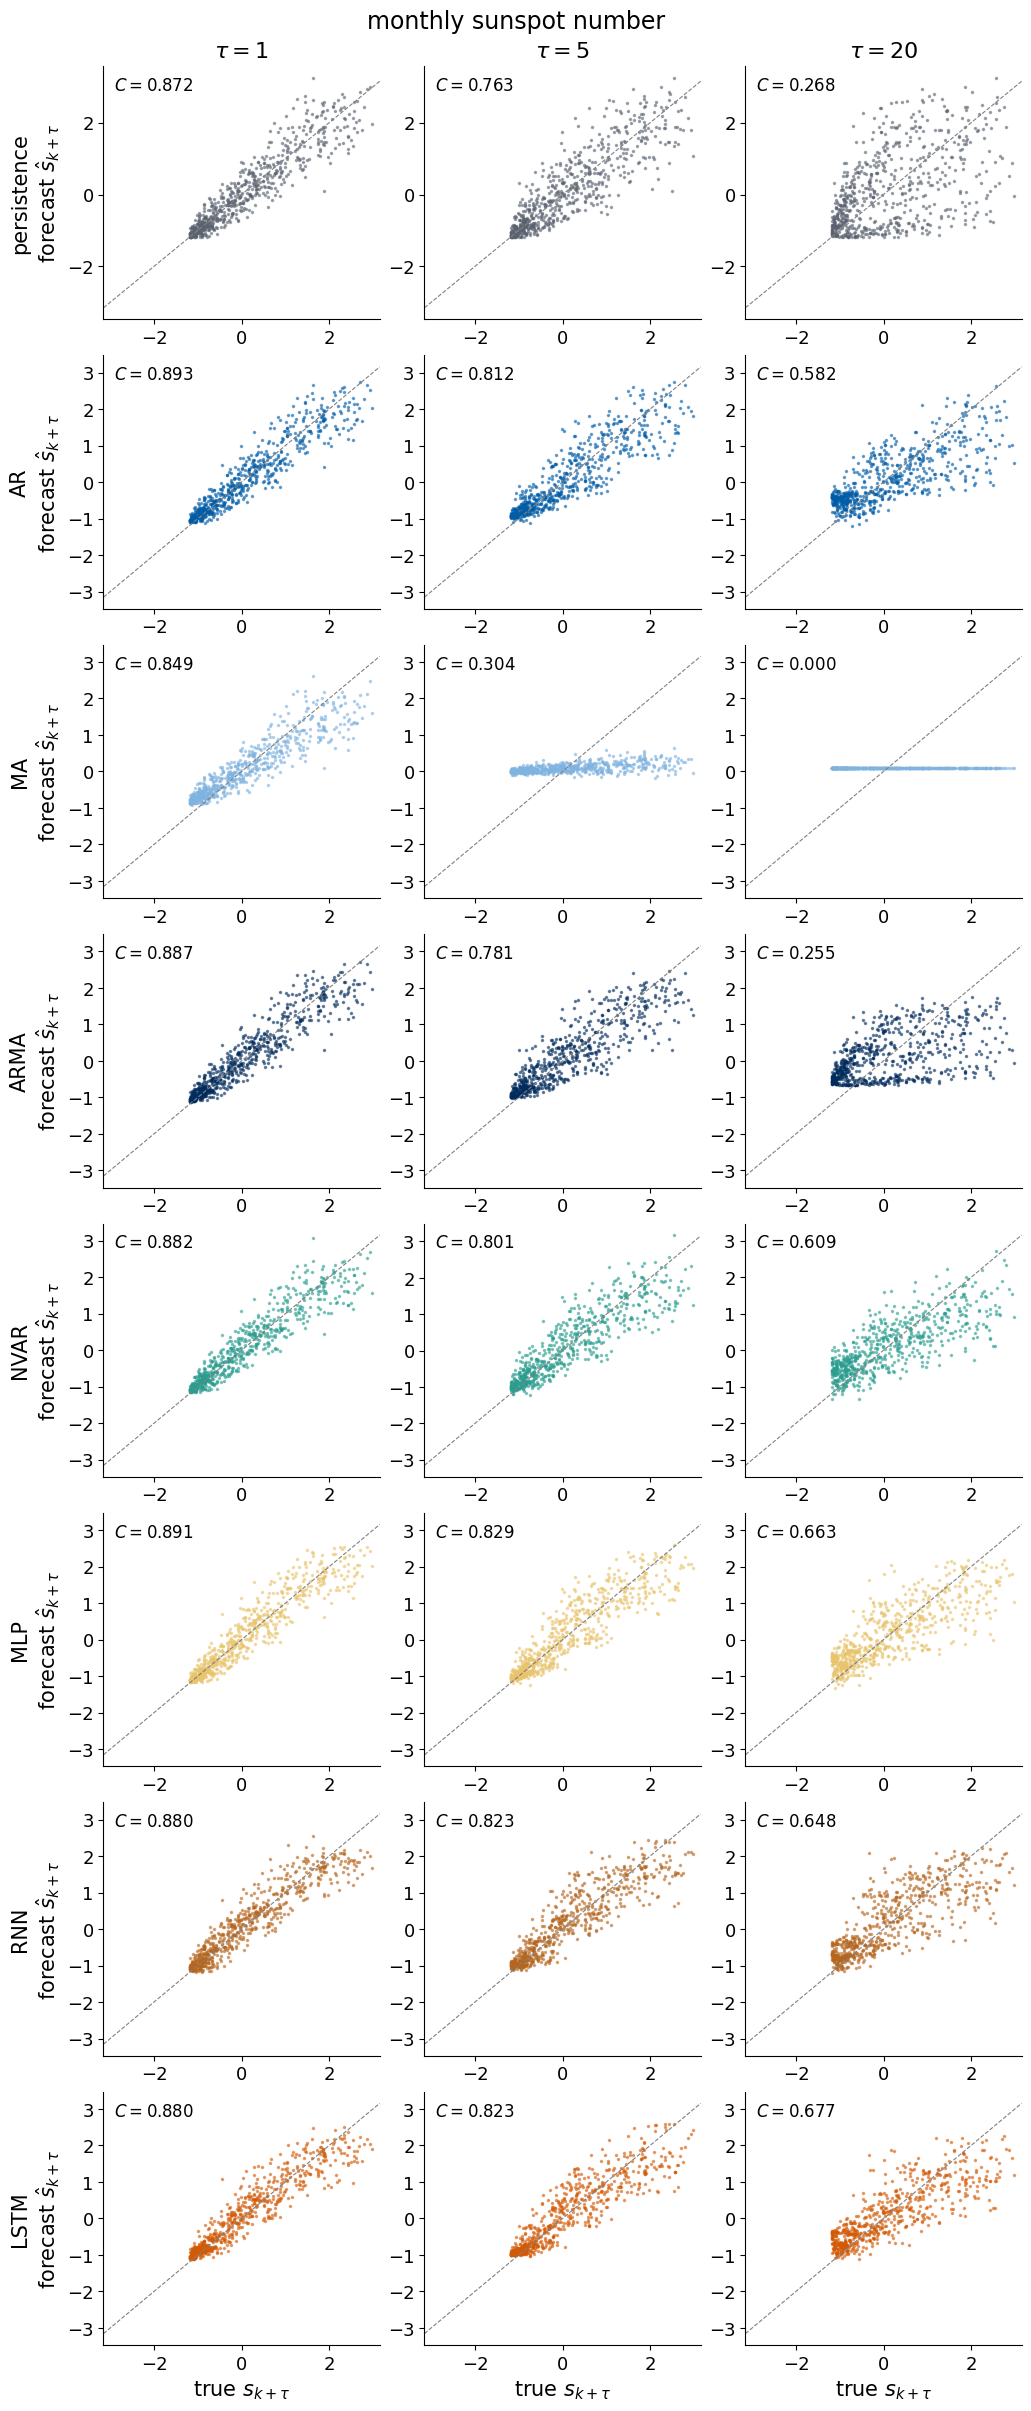

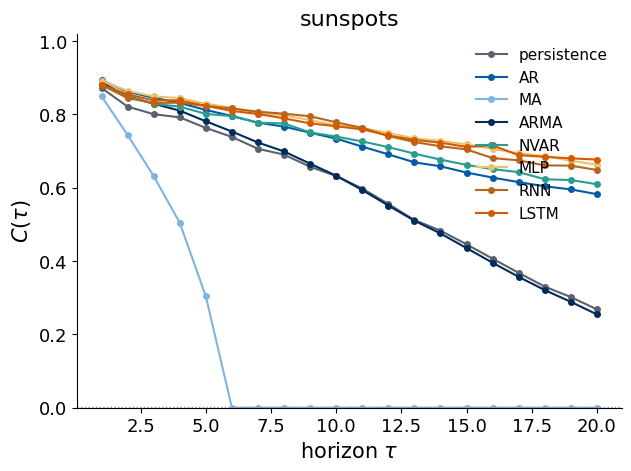

In [24]:
plot_scatter("monthly sunspot number", PREDS["sunspots"], s_sun)
plot_capacity(RESULTS, ["sunspots"], ylim=(0, 1.02))
ctot_table(RESULTS);

The test block covers 1971 to 2026, five cycles. The neural networks reach the highest total capacities, the MLP 15.364, the LSTM 15.287 and the RNN 15.179, followed by NVAR with 14.636 and AR with 14.461. Persistence reaches 11.740, and ARMA(1, 1), with 11.811, adds almost nothing to it. MA(5) reaches 3.032, since its forecast returns to the mean after five months and its C(τ) drops to zero from τ = 6. At one month all models except MA lie between C = 0.872 and 0.893, close to the square of the autocorrelation at one month, 0.918² = 0.843. The models differ at the longer horizons. Persistence falls to C(20) ≈ 0.27, while the networks keep C(20) near 0.65 to 0.68 and AR and NVAR near 0.58 to 0.61. The window of 20 months tells where in the cycle the Sun is, whether the activity rises or falls, and the models that use the shape of the window continue the cycle, which persistence cannot.

In physical units the sunspot number is never negative, so a forecast below zero is a physical error, and we count how often each model makes it. The errors of a forecast also depend on the phase of the cycle. We sort the 20-month forecasts of the best model by the change of the record over the year before the target month, a rise, a fall or a flat stretch, and compare the mean absolute errors.

In [25]:
# negative forecasts in physical units and the phase of the cycle with the largest errors
mu, sd = ssn[:N_FIT].mean(), ssn[:N_FIT].std()
for m, P in PREDS["sunspots"].items():
    print(f"{m:12s} negative forecasts: {np.mean(P * sd + mu < 0):.3f} of all forecasts")
best = max(RESULTS["sunspots"], key=lambda m: RESULTS["sunspots"][m].sum())
err = np.abs(PREDS["sunspots"][best][:, -1] - targets(s_sun, O_TEST)[:, -1]) * sd
slope = ssn[O_TEST + TAU_MAX] - ssn[O_TEST + TAU_MAX - 12]
print(f"best model {best}: mean |error| at tau = 20 is {err.mean():.1f}, "
      f"when the cycle rises over the target year {err[slope > 20].mean():.1f}, "
      f"when it falls {err[slope < -20].mean():.1f}, otherwise {err[np.abs(slope) <= 20].mean():.1f}")

persistence  negative forecasts: 0.000 of all forecasts
AR           negative forecasts: 0.000 of all forecasts
MA           negative forecasts: 0.000 of all forecasts
ARMA         negative forecasts: 0.000 of all forecasts
NVAR         negative forecasts: 0.005 of all forecasts
MLP          negative forecasts: 0.004 of all forecasts
RNN          negative forecasts: 0.003 of all forecasts
LSTM         negative forecasts: 0.001 of all forecasts
best model MLP: mean |error| at tau = 20 is 30.4, when the cycle rises over the target year 38.6, when it falls 26.4, otherwise 27.6


A small fraction of the forecasts are negative, 0.5% for NVAR, 0.4% for the MLP, 0.3% for the RNN and 0.1% for the LSTM, all near the minima of the cycles. Forecasting $\sqrt{R}$ and squaring keeps the forecast nonnegative, while a forecast of $\log(R+1)$ can still give a negative value after transforming back. The best model, the MLP, has the mean absolute error 30.4 at τ = 20 months. It is largest, 38.6, when the cycle rises during the year before the target month, 26.4 when it falls and 27.6 otherwise. The rise of a new cycle and the height it will reach are the hardest part of the forecast.

For the predictive comparison we choose the delay and coordinate count using only the first 60% of the record, the fitting block. We freeze these values, choose the ridge strength on the validation block, refit the selected readout on fitting plus validation data, and evaluate it on the same test origins as the dense-window models.

In [26]:
# Forecast settings are selected from the fitting block only; full-record plots above are descriptive.
MI_FIT = mutual_information(ssn[:N_FIT], 120)
KAPPA_FIT = first_local_min(MI_FIT)
if KAPPA_FIT is None:
    raise ValueError("No fitting-block MI minimum: choose a fallback using fitting/validation data only.")
FNN_FIT, FNN_BOTH_FIT = false_neighbour_fraction(ssn[:N_FIT], KAPPA_FIT, m_max=8, w=25)
M_EMB_FIT = embedding_dimension(FNN_FIT)
print(f"fitting-only diagnostics: kappa = {KAPPA_FIT}, m = {M_EMB_FIT}, I(0) = {MI_FIT[0]:.6f}, I(kappa) = {MI_FIT[KAPPA_FIT]:.6f}")
print("combined FNN at m=4 and m=8:", FNN_BOTH_FIT[[3, 7]])

# AR and NVAR on the embedding window: L = m values taken with the stride kappa
def embedding_ridge(s, feature_fn, m, kappa):
    k0 = (m - 1) * kappa
    fit, val, train = O_FIT[O_FIT >= k0], O_VAL[O_VAL >= k0], O_TRAIN[O_TRAIN >= k0]
    best = None
    for lam in LAMS:
        W, b = ridge_fit(feature_fn(s, fit, m, kappa), targets(s, fit), lam)
        ct = capacity(feature_fn(s, val, m, kappa) @ W + b, targets(s, val)).sum()
        if best is None or ct > best[0]:
            best = (ct, lam)
    W, b = ridge_fit(feature_fn(s, train, m, kappa), targets(s, train), best[1])
    return capacity(feature_fn(s, O_TEST, m, kappa) @ W + b, targets(s, O_TEST)), best[1]

EMBED_RESULTS = {}
if M_EMB_FIT is None:
    print("no embedding dimension below 5% false neighbours up to m = 8; the embedding window is not defined")
else:
    for label, fn in (("AR", ar_features), ("NVAR", nvar_features)):
        C_emb, lam = embedding_ridge(s_sun, fn, M_EMB_FIT, KAPPA_FIT)
        EMBED_RESULTS[label] = dict(C=C_emb.copy(), Ctot=float(C_emb.sum()), ridge_penalty=float(lam),
                                   m=int(M_EMB_FIT), kappa=int(KAPPA_FIT))
        print(f"{label:5s} on the embedding window (m = {M_EMB_FIT}, kappa = {KAPPA_FIT}, lambda = {lam:.0e}): C_tot {C_emb.sum():6.3f}   "
              f"validation-chosen window: C_tot {RESULTS['sunspots'][label].sum():6.3f}")

fitting-only diagnostics: kappa = 23, m = 4, I(0) = 2.108171, I(kappa) = 0.182774
combined FNN at m=4 and m=8: [0.06187729 0.11900826]
AR    on the embedding window (m = 4, kappa = 23, lambda = 1e-06): C_tot 14.306   validation-chosen window: C_tot 14.461
NVAR  on the embedding window (m = 4, kappa = 23, lambda = 1e+02): C_tot 15.345   validation-chosen window: C_tot 14.636


The fitting-block diagnostics select 4 values spaced by 23 months, spanning 70 samples. With this window and the ridge penalties chosen on the validation block, AR reaches $C_{\rm tot}=14.306$ and NVAR 15.345, compared with 14.461 and 14.636 for the windows of recent values chosen on the validation block. These results use no test observations to choose the embedding settings. With this window NVAR gains about 0.7 units of capacity and AR loses 0.15.

In [27]:
print(f"total runtime {time.time() - t_start:.0f} s")

# Export the measurements from this execution; keep descriptive and predictive scopes distinct.
import hashlib, json
from pathlib import Path

def result_json_value(value):
    if isinstance(value, dict):
        return {str(key): result_json_value(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [result_json_value(item) for item in value]
    if isinstance(value, np.ndarray):
        return result_json_value(value.tolist())
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return result_json_value(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

run_results = {
    "schema_version": 1,
    "protocol": {
        "n_samples": N, "n_fit": N_FIT, "n_validation": N_VAL,
        "n_fit_origins": len(O_FIT), "n_validation_origins": len(O_VAL),
        "n_final_fit_origins": len(O_TRAIN), "n_test_origins": len(O_TEST),
        "horizons": TAUS, "dense_window_max": L_MAX,
        "scaling": "mean and standard deviation of fitting block only",
        "refit_on_fit_plus_validation": ["AR", "NVAR", "MA", "ARMA", "MLP"],
        "best_fitting_checkpoint_without_refit": ["RNN", "LSTM"],
        "MLP_early_stopping": "random internal holdout; chronological block selects hyperparameters",
    },
    "diagnostics_descriptive_full_record": {
        "scope": "full available record; not used to choose predictive embedding settings",
        "mutual_information": MI, "kappa": KAPPA, "m_ratio_threshold": M_EMB,
        "fnn_ratio": FNN, "fnn_combined": FNN_BOTH,
    },
    "diagnostics_predictive_fitting_block": {
        "scope": "first N_FIT samples only; frozen before validation/test scoring",
        "mutual_information": MI_FIT, "kappa": KAPPA_FIT, "m_ratio_threshold": M_EMB_FIT,
        "fnn_ratio": FNN_FIT, "fnn_combined": FNN_BOTH_FIT,
    },
    "capacity": {series: {model: {"C": values, "Ctot": float(values.sum())}
                          for model, values in model_results.items()}
                 for series, model_results in RESULTS.items()},
    "chosen_model_settings": CHOSEN_BY_SERIES,
    "sparse_embedding_comparison": EMBED_RESULTS,
    "software": {"numpy": np.__version__, "pandas": pd.__version__,
                 "scipy": scipy.__version__, "jax": jax.__version__,
                 "flax": flax.__version__, "sklearn": sklearn.__version__,
                 "statsmodels": statsmodels.__version__},
}

run_results["record"] = {
    "source_file": SUN_FILE, "source_sha256": hashlib.sha256(Path(SUN_FILE).read_bytes()).hexdigest(),
    "first_month": f"{int(sun.year.iloc[0]):04d}-{int(sun.month.iloc[0]):02d}",
    "last_month": f"{int(sun.year.iloc[-1]):04d}-{int(sun.month.iloc[-1]):02d}",
    "n_months": len(ssn), "provisional_months": int((sun.definitive == 0).sum()),
    "mean": float(ssn.mean()), "std": float(ssn.std()), "median": float(np.median(ssn)),
    "min": float(ssn.min()), "max": float(ssn.max()),
    "maximum_decimal_year": float(t_sun[ssn.argmax()]), "skewness": float(scipy.stats.skew(ssn)),
    "zero_months": int(np.sum(ssn == 0)), "months_without_station_statistics": int((sun.n_obs < 0).sum()),
    "last_year_observations_min": int(sun.n_obs.iloc[-12:].min()),
    "last_year_observations_max": int(sun.n_obs.iloc[-12:].max()),
    "test_first_decimal_year": float(t_sun[O_TEST[0]]), "test_last_decimal_year": float(t_sun[-1]),
}
_export_f, _export_psd = periodogram(ssn, DT)
_export_peak_indices = np.argsort(_export_psd[1:])[::-1][:5] + 1
run_results["diagnostics_descriptive_full_record"].update(
    autocorrelation=rho, correlation_time_months=correlation_time(rho),
    first_autocorrelation_minimum_lag_months=int(np.argmin(rho[:12 * 9])),
    second_autocorrelation_maximum_lag_months=int(12 * 7 + np.argmax(rho[12 * 7:12 * 16])),
    strongest_periodogram_periods_years=1 / _export_f[_export_peak_indices],
    variance_fraction_8_to_15_year_periods=float(
        _export_psd[(_export_f > 1 / 15) & (_export_f < 1 / 8)].sum() / _export_psd[1:].sum()))
_export_mu, _export_sd = ssn[:N_FIT].mean(), ssn[:N_FIT].std()
_export_best = max(RESULTS["sunspots"], key=lambda model: RESULTS["sunspots"][model].sum())
_export_errors = np.abs(PREDS["sunspots"][_export_best][:, -1] - targets(s_sun, O_TEST)[:, -1]) * _export_sd
_export_slope = ssn[O_TEST + TAU_MAX] - ssn[O_TEST + TAU_MAX - 12]
_export_masks = {"rising": _export_slope > 20, "falling": _export_slope < -20,
                 "other": np.abs(_export_slope) <= 20}
run_results["physical_error_diagnostics"] = {
    "selection_scope": "exploratory: model selected by test capacity; phase assigned retrospectively",
    "model": _export_best, "horizon_months": TAU_MAX,
    "negative_forecast_fraction": {model: float(np.mean(pred * _export_sd + _export_mu < 0))
                                   for model, pred in PREDS["sunspots"].items()},
    "mean_absolute_error": float(_export_errors.mean()),
    "phase_mean_absolute_error": {label: float(_export_errors[mask].mean()) if mask.any() else None
                                  for label, mask in _export_masks.items()},
    "phase_counts": {label: int(mask.sum()) for label, mask in _export_masks.items()},
}
_export_path = Path("figures/numbers_sunspots.json")
_export_path.parent.mkdir(parents=True, exist_ok=True)
_export_path.write_text(json.dumps(result_json_value(run_results), indent=2, allow_nan=False) + "\n")
print(f"Fresh-run numeric results written to {_export_path}")


total runtime 46 s
Fresh-run numeric results written to figures/numbers_sunspots.json


## References

- WDC-SILSO, Royal Observatory of Belgium, Brussels, *Monthly mean total sunspot number*, version 2.0, <https://www.sidc.be/SILSO/datafiles>, licence CC BY-NC 4.0
- F. Clette, L. Svalgaard, J. M. Vaquero, E. W. Cliver, *Revisiting the sunspot number*, Space Sci. Rev. **186**, 35 (2014), [doi:10.1007/s11214-014-0074-2](https://doi.org/10.1007/s11214-014-0074-2)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)